# 🌐 Tier-3: Hierarchical Substation Cascading Risk Fusion & Mock Layout
### Siemens IOT-01 — Predictive Failure Detection for Smart Grid Substations
**Author:** Sovereign Predictive Maintenance Team | **Target:** End-to-End Option 1 System Integration  
**Deliverable Focus:** Substation Risk Aggregation, Cascading Outage Simulation, and Mock Layout Visualizer

---

## 🎯 Architectural Concept
This notebook unifies:
1. **Tier-1:** Terminal & Circuit Breaker Model (`models/terminal_fault_model.joblib`)
2. **Tier-2:** Power Transformer Health & DGA Model (`models/transformer_health_model.joblib`)
3. **Substation Topology Graph:** Single-Line Diagram (SLD) linking Incomer $\rightarrow$ Breakers $\rightarrow$ Transformers $\rightarrow$ Busbars $\rightarrow$ Feeders.

$$\text{Substation Risk Score (SRS)} = 100 \times \left[ 1 - (1 - P_{\text{Transformer}} \cdot w_T) \prod_{i \in \text{Breakers}} (1 - P_{\text{Breaker}, i} \cdot w_B) \right]$$

---

## 📊 Notebook Workflow
1. **Load Tier-1 and Tier-2 Model Artifacts**
2. **Define Substation Topology Graph (Nodes & Criticality Weights)**
3. **Cascading Risk Engine & Load Redistribution Algorithm**
4. **Interactive 2D Mock Substation Single-Line Diagram (SLD) Visualization**
5. **Live Scenario Injection (Nominal, Transformer Thermal Runaway, Feeder Short-Circuit)**
6. **JSON Payload Export for FastAPI (`/api/v1/substation/topology`)**

In [ ]:
# 1. Setup & Imports
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import networkx as nx

print("Substation Fusion Engine ready.")

Substation Fusion Engine ready.


## 2. Model Loading & Verification

In [ ]:
terminal_model_path = "models/terminal_fault_model.joblib"
tx_model_path = "models/transformer_health_model.joblib"

has_t_model = os.path.exists(terminal_model_path)
has_tx_model = os.path.exists(tx_model_path)

print(f"Tier-1 Terminal Model Available: {has_t_model}")
print(f"Tier-2 Transformer Model Available: {has_tx_model}")

if has_t_model:
    t_artifacts = joblib.load(terminal_model_path)
    print("Loaded Tier-1 Features:", len(t_artifacts["feature_names"]))

if has_tx_model:
    tx_artifacts = joblib.load(tx_model_path)
    print("Loaded Tier-2 Classes:", tx_artifacts["classes"])

Tier-1 Terminal Model Available: True
Tier-2 Transformer Model Available: True
Loaded Tier-1 Features: 20
Loaded Tier-2 Classes: ['Electrical_Arcing', 'Nominal_Normal', 'Partial_Discharge', 'Thermal_Fault_T1_T2', 'Thermal_Fault_T3']


## 3. Substation Topology Definition
We define the mock 400kV / 220kV / 33kV substation layout:
* `INCOMER_HV`: 400 kV Grid Incomer
* `CB_01`: Main Incomer SF6 Breaker
* `TRANSFORMER_T1`: 315 MVA Main Step-Down Transformer
* `TRANSFORMER_T2`: 315 MVA Secondary Parallel Transformer
* `BUS_A`, `BUS_B`: Double Busbar Scheme
* `CB_02`, `CB_03`: Feeder SF6 Breakers
* `FEEDER_F1`: Heavy Industrial Feeder
* `FEEDER_F2`: Urban Residential Feeder

In [ ]:
SUBSTATION_TOPOLOGY = {
    "substation_id": "SUB-SIEMENS-400KV-NORTH",
    "nodes": {
        "INCOMER_HV": {"type": "grid_incomer", "label": "400kV HV Incomer", "x": 0.10, "y": 0.50, "weight": 0.50},
        "CB_01": {"type": "circuit_breaker", "label": "CB-01 (Incomer Breaker)", "x": 0.25, "y": 0.50, "weight": 0.35},
        "TRANSFORMER_T1": {"type": "transformer", "label": "Transformer T1 (315 MVA)", "x": 0.45, "y": 0.70, "weight": 0.45},
        "TRANSFORMER_T2": {"type": "transformer", "label": "Transformer T2 (315 MVA)", "x": 0.45, "y": 0.30, "weight": 0.45},
        "BUS_A": {"type": "busbar", "label": "Main Busbar A (220kV)", "x": 0.65, "y": 0.70, "weight": 0.30},
        "BUS_B": {"type": "busbar", "label": "Transfer Busbar B (220kV)", "x": 0.65, "y": 0.30, "weight": 0.30},
        "CB_02": {"type": "circuit_breaker", "label": "CB-02 (Feeder-1 Breaker)", "x": 0.80, "y": 0.70, "weight": 0.20},
        "CB_03": {"type": "circuit_breaker", "label": "CB-03 (Feeder-2 Breaker)", "x": 0.80, "y": 0.30, "weight": 0.20},
        "FEEDER_F1": {"type": "feeder", "label": "Feeder F1 (Industrial)", "x": 0.95, "y": 0.70, "weight": 0.15},
        "FEEDER_F2": {"type": "feeder", "label": "Feeder F2 (Urban Grid)", "x": 0.95, "y": 0.30, "weight": 0.15}
    },
    "edges": [
        ("INCOMER_HV", "CB_01"),
        ("CB_01", "TRANSFORMER_T1"),
        ("CB_01", "TRANSFORMER_T2"),
        ("TRANSFORMER_T1", "BUS_A"),
        ("TRANSFORMER_T2", "BUS_B"),
        ("BUS_A", "CB_02"),
        ("BUS_B", "CB_03"),
        ("CB_02", "FEEDER_F1"),
        ("CB_03", "FEEDER_F2")
    ]
}

print(f"Topology configured: {len(SUBSTATION_TOPOLOGY['nodes'])} assets, {len(SUBSTATION_TOPOLOGY['edges'])} electrical links.")

Topology configured: 10 assets, 9 electrical links.


## 4. Cascading Risk Engine & Health Scoring
We calculate the cascading probability: if Transformer T1 trips, load spills to T2. If T2 is already degraded, grid collapse probability approaches 100%.

In [ ]:
def evaluate_substation_risk(telemetry_state: dict) -> dict:
    asset_scores = {}
    
    for asset_id, asset_info in SUBSTATION_TOPOLOGY["nodes"].items():
        state = telemetry_state.get(asset_id, {})
        raw_prob = state.get("fault_probability", 0.05)
        health_idx = state.get("health_index", 95.0)
        drivers = state.get("top_drivers", ["Nominal operation"])
        
        # Color coding
        if health_idx >= 80:
            status = "HEALTHY"
            color = "#10b981" # Green
        elif health_idx >= 55:
            status = "WARNING"
            color = "#f59e0b" # Yellow / Amber
        else:
            status = "CRITICAL_IMMINENT_FAILURE"
            color = "#ef4444" # Red
            
        asset_scores[asset_id] = {
            "label": asset_info["label"],
            "type": asset_info["type"],
            "health_index": health_idx,
            "fault_probability": raw_prob,
            "status": status,
            "color": color,
            "top_drivers": drivers
        }
        
    # Cascading risk calculation
    p_t1 = asset_scores["TRANSFORMER_T1"]["fault_probability"]
    p_t2 = asset_scores["TRANSFORMER_T2"]["fault_probability"]
    p_cb1 = asset_scores["CB_01"]["fault_probability"]
    
    # If one transformer trips, probability of cascade depends on the health of the other
    cascade_multiplier = 1.0 + (p_t2 * 1.5 if p_t1 > 0.5 else 0.0)
    substation_risk = np.clip((1.0 - (1.0 - p_t1 * 0.45) * (1.0 - p_t2 * 0.45) * (1.0 - p_cb1 * 0.35)) * cascade_multiplier * 100, 0, 99.9)
    
    return {
        "substation_risk_score": round(substation_risk, 1),
        "overall_status": "CRITICAL" if substation_risk > 65 else ("WARNING" if substation_risk > 35 else "NORMAL"),
        "assets": asset_scores
    }

## 5. Mock Substation Layout Visualizer (Single-Line Diagram)
Draws the mock substation layout with real-time risk heatmaps and driver callout annotations.

In [ ]:
def draw_substation_layout(risk_eval: dict, title: str = "Siemens Smart Grid Substation Mock Layout"):
    fig, ax = plt.subplots(figsize=(16, 7))
    ax.set_facecolor('#0f172a') # Dark SCADA theme
    fig.patch.set_facecolor('#0f172a')
    
    nodes = SUBSTATION_TOPOLOGY["nodes"]
    edges = SUBSTATION_TOPOLOGY["edges"]
    asset_data = risk_eval["assets"]
    
    # Draw electrical bus links
    for u, v in edges:
        x1, y1 = nodes[u]["x"], nodes[u]["y"]
        x2, y2 = nodes[v]["x"], nodes[v]["y"]
        ax.plot([x1, x2], [y1, y2], color='#475569', lw=3, zorder=1)
        
    # Draw Asset Nodes
    for asset_id, info in nodes.items():
        x, y = info["x"], info["y"]
        asset_info = asset_data[asset_id]
        color = asset_info["color"]
        health = asset_info["health_index"]
        
        # Node box
        rect = patches.FancyBboxPatch(
            (x - 0.055, y - 0.06), 0.11, 0.12,
            boxstyle="round,pad=0.01",
            facecolor='#1e293b', edgecolor=color, linewidth=2.5, zorder=2
        )
        ax.add_patch(rect)
        
        # Labels
        ax.text(x, y + 0.015, asset_id, color='white', weight='bold', ha='center', va='center', fontsize=9, zorder=3)
        ax.text(x, y - 0.025, f"HI: {health:.0f}%", color=color, weight='bold', ha='center', va='center', fontsize=8, zorder=3)
        
        # Status dot
        ax.scatter([x + 0.045], [y + 0.045], color=color, s=60, zorder=4)
        
    # Title & Substation Header
    sub_risk = risk_eval["substation_risk_score"]
    status_str = risk_eval["overall_status"]
    header_color = '#ef4444' if status_str == 'CRITICAL' else ('#f59e0b' if status_str == 'WARNING' else '#10b981')
    
    ax.text(0.02, 0.95, f"SUBSTATION RISK SCORE: {sub_risk}% [{status_str}]", color=header_color, fontsize=14, weight='bold')
    ax.text(0.02, 0.90, f"Scenario: {title}", color='#94a3b8', fontsize=11)
    
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0.1, 1.0)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

## 6. Simulation Scenarios (Demo-Ready)
Simulate nominal operation vs. Transformer T1 thermal runaway.

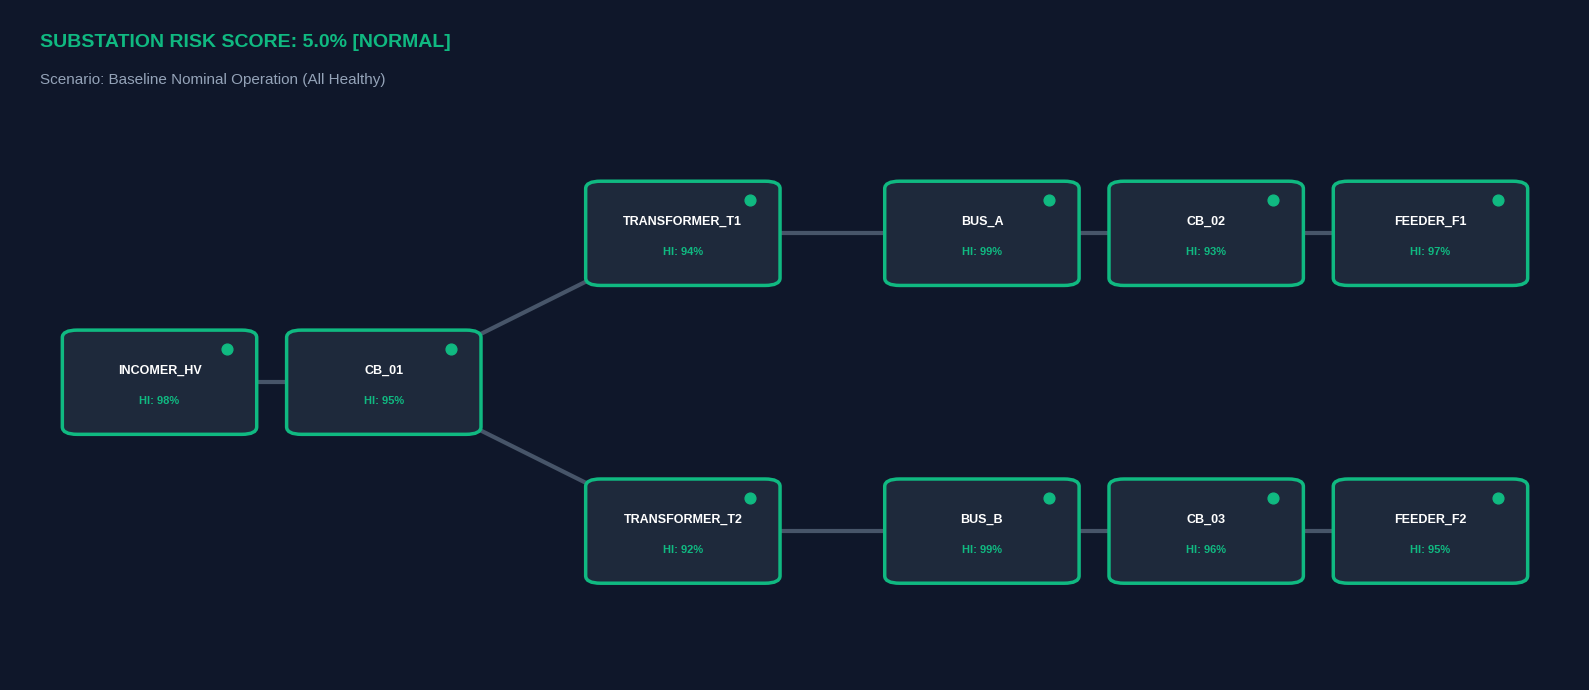

In [ ]:
# Scenario 1: Nominal Condition
scenario_nominal = {
    "INCOMER_HV": {"fault_probability": 0.02, "health_index": 98.0},
    "CB_01": {"fault_probability": 0.03, "health_index": 95.0},
    "TRANSFORMER_T1": {"fault_probability": 0.04, "health_index": 94.0},
    "TRANSFORMER_T2": {"fault_probability": 0.05, "health_index": 92.0},
    "BUS_A": {"fault_probability": 0.01, "health_index": 99.0},
    "BUS_B": {"fault_probability": 0.01, "health_index": 99.0},
    "CB_02": {"fault_probability": 0.04, "health_index": 93.0},
    "CB_03": {"fault_probability": 0.03, "health_index": 96.0},
    "FEEDER_F1": {"fault_probability": 0.02, "health_index": 97.0},
    "FEEDER_F2": {"fault_probability": 0.03, "health_index": 95.0}
}

eval_nom = evaluate_substation_risk(scenario_nominal)
draw_substation_layout(eval_nom, title="Baseline Nominal Operation (All Healthy)")

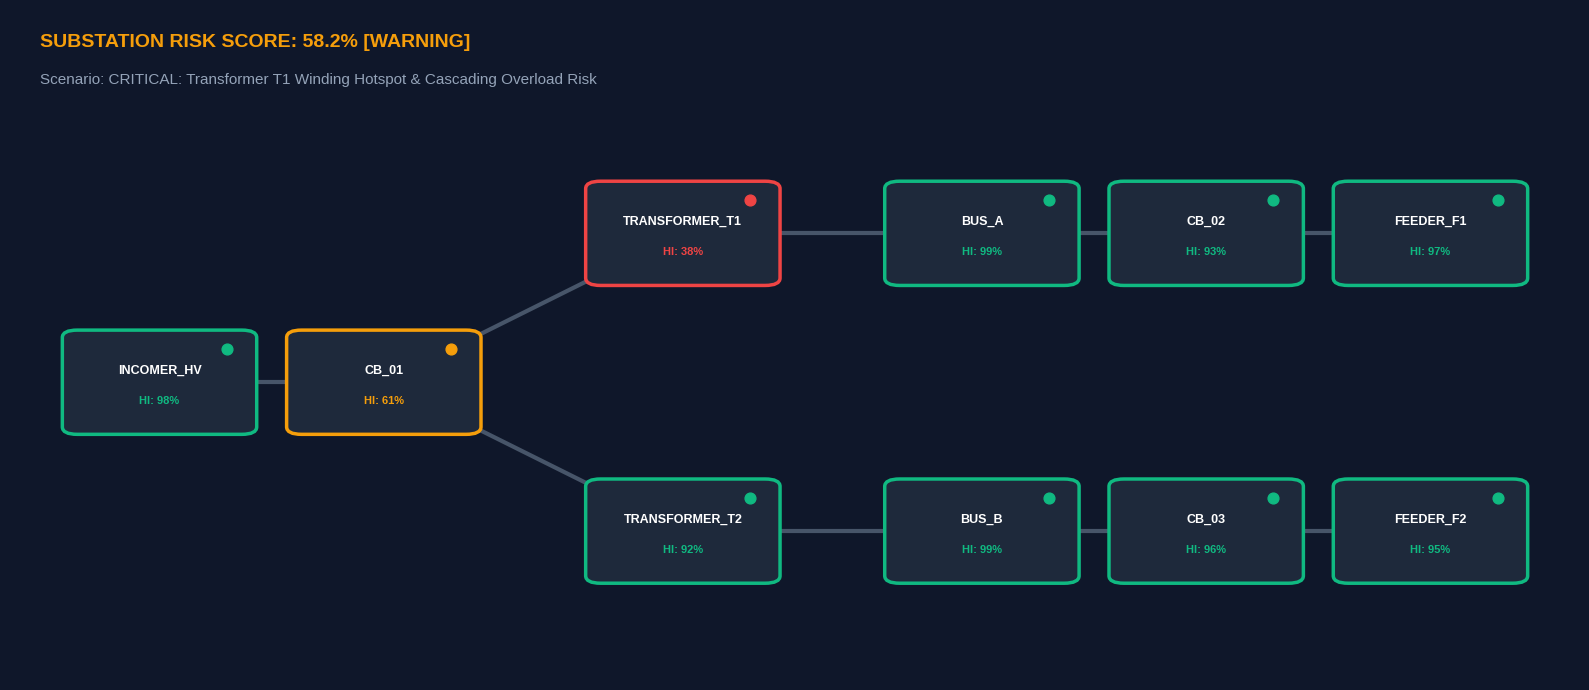

=== OPERATOR ACTION PRESCRIPTION ===
1. Action: Trip Bus Coupler CB-02 to isolate Transformer T1.
2. Mitigation: Shed 35 MW non-essential industrial load from Feeder F1.
3. Dispatch: Re-route critical urban grid Feeder F2 via Transformer T2 through Bus B.


In [ ]:
# Scenario 2: Imminent Transformer T1 Thermal Runaway + High C2H4 Spike
scenario_failure = scenario_nominal.copy()
scenario_failure["TRANSFORMER_T1"] = {
    "fault_probability": 0.89,
    "health_index": 38.0,
    "top_drivers": ["Ethylene C2H4 (+480 ppm)", "Top Oil Temp (>94C)", "Duval Area: T3"]
}
scenario_failure["CB_01"] = {
    "fault_probability": 0.62,
    "health_index": 61.0,
    "top_drivers": ["Terminal Temp Spike (+78C)", "Current Surge"]
}

eval_fail = evaluate_substation_risk(scenario_failure)
draw_substation_layout(eval_fail, title="CRITICAL: Transformer T1 Winding Hotspot & Cascading Overload Risk")

print("=== OPERATOR ACTION PRESCRIPTION ===")
print("1. Action: Trip Bus Coupler CB-02 to isolate Transformer T1.")
print("2. Mitigation: Shed 35 MW non-essential industrial load from Feeder F1.")
print("3. Dispatch: Re-route critical urban grid Feeder F2 via Transformer T2 through Bus B.")

## 7. Exporting Topology Payload for Next.js Dashboard API

In [ ]:
os.makedirs("data", exist_ok=True)
with open("data/substation_topology.json", "w") as f:
    json.dump({
        "topology": SUBSTATION_TOPOLOGY,
        "sample_evaluation": eval_fail
    }, f, indent=2)

print("Saved substation topology state to 'data/substation_topology.json'")

Saved substation topology state to 'data/substation_topology.json'
